In [1]:
import numpy as np 
import pandas as pd 

import seaborn as sns 
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import LabelEncoder
from sklearn.impute import SimpleImputer



In [2]:
df = pd.read_csv("attrition.csv")
df.head(15)

,Age,MonthlyIncome,JobSatisfaction,DistanceFromHome,YearsAtCompany,OverTime,Attrition
0,30,15058,3.0,34,13,No,0
1,46,10795,2.0,22,22,Yes,0
2,25,7235,3.0,39,15,Yes,0
3,45,15493,4.0,33,23,No,0
4,37,17421,3.0,11,14,Yes,0
5,32,16751,4.0,21,1,Yes,0
6,52,5999,2.0,37,24,No,0
7,56,18005,NaN,19,3,No,0
8,24,6021,1.0,2,10,No,0
9,56,9450,NaN,17,6,No,0


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Age               3000 non-null   int64  
 1   MonthlyIncome     3000 non-null   int64  
 2   JobSatisfaction   2800 non-null   float64
 3   DistanceFromHome  3000 non-null   int64  
 4   YearsAtCompany    3000 non-null   int64  
 5   OverTime          3000 non-null   object 
 6   Attrition         3000 non-null   int64  
dtypes: float64(1), int64(5), object(1)
memory usage: 164.2+ KB


In [4]:
df.describe()

,Age,MonthlyIncome,JobSatisfaction,DistanceFromHome,YearsAtCompany,Attrition
count,3000.000000,3000.000000,2800.000000,3000.000000,3000.000000,3000.000000
mean,40.464000,12530.414667,2.557143,20.196667,11.989000,0.067667
std,11.052032,11636.242498,1.109068,11.292704,7.220498,0.251215
min,22.000000,3009.000000,1.000000,1.000000,0.000000,0.000000
25%,31.000000,7302.500000,2.000000,11.000000,6.000000,0.000000
50%,40.000000,11584.500000,3.000000,20.000000,12.000000,0.000000
75%,50.000000,15928.750000,4.000000,30.000000,18.000000,0.000000
max,59.000000,148323.000000,4.000000,39.000000,24.000000,1.000000


In [5]:
df.isna().sum()

Age                   0
MonthlyIncome         0
JobSatisfaction     200
DistanceFromHome      0
YearsAtCompany        0
OverTime              0
Attrition             0
dtype: int64

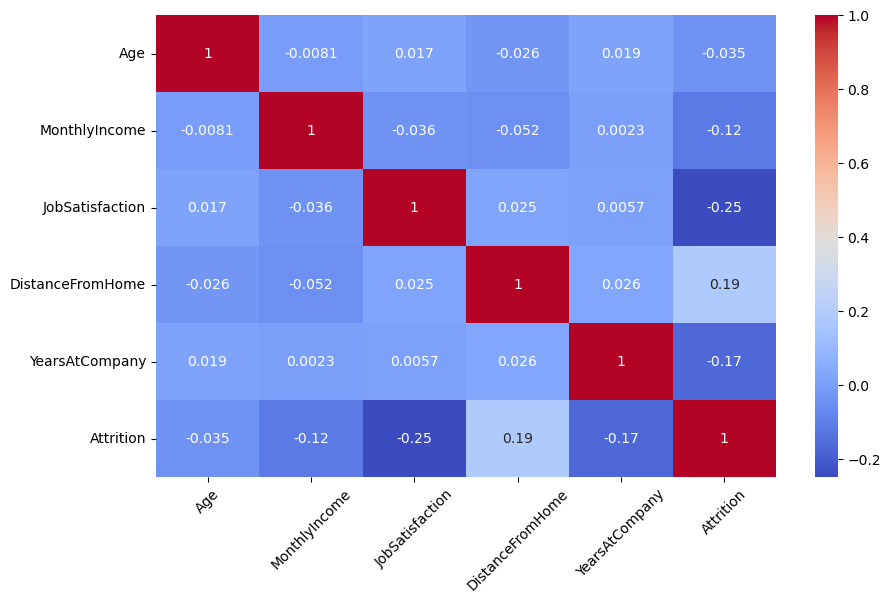

In [6]:
plt.figure(figsize = (10 ,6))
sns.heatmap(df.corr(numeric_only= True) ,annot = True ,cmap = 'coolwarm')
plt.xticks(rotation = 45)
plt.show()

In [7]:
df["JobSatisfaction"].skew()

np.float64(-0.0735727052110381)

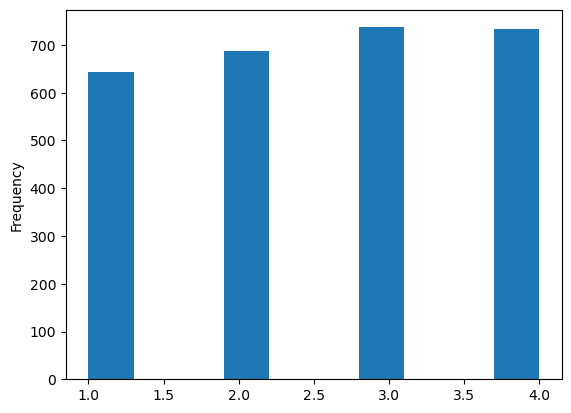

In [8]:
df["JobSatisfaction"].plot(kind= 'hist')
plt.show()

In [9]:
X = df.drop("Attrition",  axis = 1)
y = df['Attrition']

In [10]:
X_train , X_test , y_train , y_test = train_test_split(X , y , test_size=.2 , random_state=1234)

In [11]:
impute = SimpleImputer(strategy='mean')
X_train[["JobSatisfaction"]] = impute.fit_transform(X_train[["JobSatisfaction"]])
X_test[["JobSatisfaction"]] = impute.transform(X_test[["JobSatisfaction"]])

In [12]:
X_train.isna().sum()

Age                 0
MonthlyIncome       0
JobSatisfaction     0
DistanceFromHome    0
YearsAtCompany      0
OverTime            0
dtype: int64

In [13]:
le = LabelEncoder()
X_train["OverTime"] = le.fit_transform(X_train["OverTime"])
X_test["OverTime"] = le.transform(X_test["OverTime"])

In [14]:
X_train.head()

,Age,MonthlyIncome,JobSatisfaction,DistanceFromHome,YearsAtCompany,OverTime
204,22,5771,2.0,29,4,0
2746,46,7989,4.0,32,22,1
2592,30,13272,2.0,26,12,1
1687,57,7132,4.0,8,23,0
2687,52,11257,4.0,29,7,0


In [15]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

In [68]:
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import accuracy_score , confusion_matrix , classification_report

In [58]:
logistic = LogisticRegression()
logistic.fit(X_train_scaled , y_train)

LogisticRegression()

In [59]:
print(logistic.score(X_train_scaled , y_train))

0.9808333333333333


In [60]:
y_pred_log = logistic.predict(X_test_scaled)

In [61]:
print(accuracy_score(y_test, y_pred_log))

0.9866666666666667


In [62]:
acc = accuracy_score(y_pred_log , y_test)
cr = classification_report(y_pred_log , y_test)

print(f"Accuracy Score: {acc:.4f}")
print("*" * 50)
print("\nClassification Report:")
print(cr)

Accuracy Score: 0.9867
**************************************************

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.99      0.99       566
           1       0.81      1.00      0.89        34

    accuracy                           0.99       600
   macro avg       0.90      0.99      0.94       600
weighted avg       0.99      0.99      0.99       600



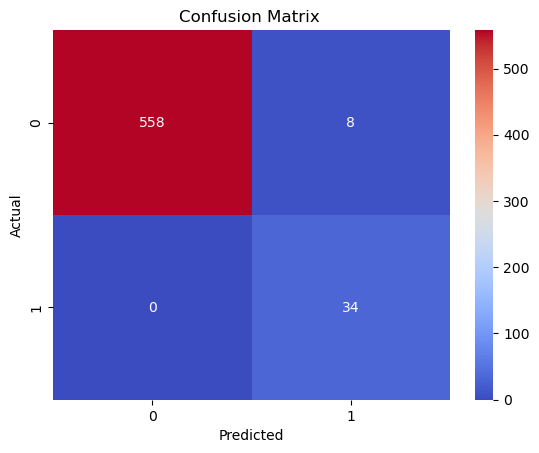

In [143]:
cm = confusion_matrix(y_pred_log , y_test)

sns.heatmap(cm , cmap = 'coolwarm', fmt= "g" , annot = True)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix ')
plt.show()

In [64]:
naive = GaussianNB()
naive.fit(X_train_scaled , y_train)

GaussianNB()

In [65]:
print(naive.score(X_train_scaled , y_train))

0.9520833333333333


In [66]:
y_pred_naive = naive.predict(X_test_scaled)

In [67]:
print(accuracy_score(y_test, y_pred_naive))

0.9383333333333334


In [69]:
acc = accuracy_score(y_pred_naive , y_test)
cr = classification_report(y_pred_naive , y_test)

print(f"Accuracy Score: {acc:.4f}")
print("*" * 50)
print("\nClassification Report:")
print(cr)

Accuracy Score: 0.9383
**************************************************

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.94      0.97       587
           1       0.21      0.69      0.33        13

    accuracy                           0.94       600
   macro avg       0.60      0.82      0.65       600
weighted avg       0.98      0.94      0.95       600



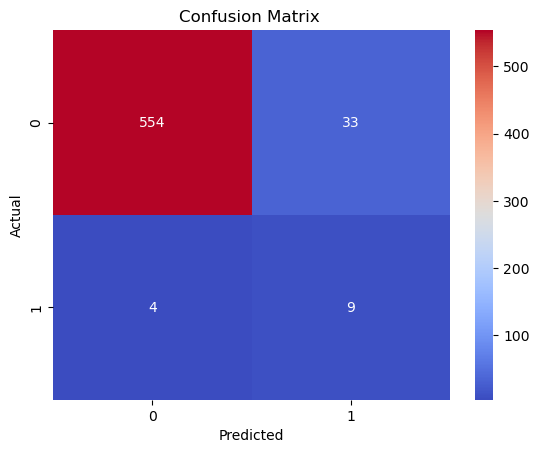

In [144]:
cm = confusion_matrix(y_pred_naive , y_test)

sns.heatmap(cm , cmap = 'coolwarm', fmt= "g" , annot = True)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix ')
plt.show()

In [94]:
knn = KNeighborsClassifier(n_neighbors = 5 , metric = 'minkowski', p = 2)
knn.fit(X_train_scaled , y_train)

KNeighborsClassifier()

In [95]:
print(knn.score(X_train_scaled , y_train))

0.9766666666666667


In [96]:
y_pred_knn = logistic.predict(X_test_scaled)

In [97]:
print(accuracy_score(y_test, y_pred_knn))

0.9533333333333334


In [98]:
acc = accuracy_score(y_pred_knn , y_test)
cr = classification_report(y_pred_knn , y_test)

print(f"Accuracy Score: {acc:.4f}")
print("*" * 50)
print("\nClassification Report:")
print(cr)

Accuracy Score: 0.9533
**************************************************

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.96      0.98       572
           1       0.50      0.75      0.60        28

    accuracy                           0.95       600
   macro avg       0.74      0.86      0.79       600
weighted avg       0.96      0.95      0.96       600



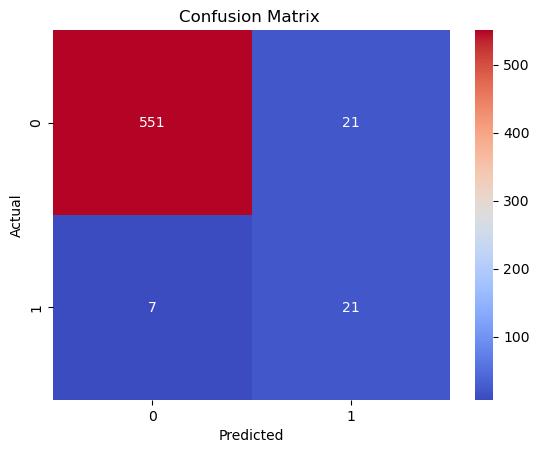

In [145]:
cm = confusion_matrix(y_pred_knn , y_test)

sns.heatmap(cm , cmap = 'coolwarm', fmt= "g" , annot = True)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix ')
plt.show()

In [101]:
svc = SVC(gamma = 'auto' , kernel = 'linear' , C = .1)
svc.fit(X_train_scaled , y_train)

SVC(C=0.1, gamma='auto', kernel='linear')

In [102]:
print(svc.score(X_train_scaled , y_train))

0.9775


In [103]:
y_pred_svc = svc.predict(X_test_scaled)

In [104]:
print(accuracy_score(y_test, y_pred_svc))

0.9783333333333334


In [105]:
acc = accuracy_score(y_pred_svc , y_test)
cr = classification_report(y_pred_svc , y_test)

print(f"Accuracy Score: {acc:.4f}")
print("*" * 50)
print("\nClassification Report:")
print(cr)

Accuracy Score: 0.9783
**************************************************

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.98      0.99       571
           1       0.69      1.00      0.82        29

    accuracy                           0.98       600
   macro avg       0.85      0.99      0.90       600
weighted avg       0.99      0.98      0.98       600



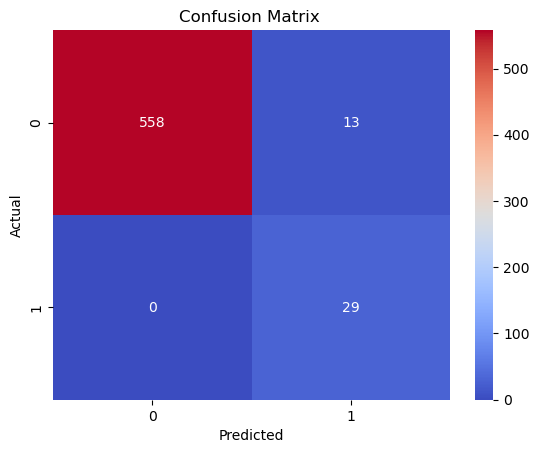

In [146]:
cm = confusion_matrix(y_pred_svc , y_test)

sns.heatmap(cm , cmap = 'coolwarm', fmt= "g" , annot = True)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix ')
plt.show()

In [113]:
from sklearn.model_selection import GridSearchCV

In [122]:
grid_pram = {
    "C" : [0.1 , 1 ,10 ,100],
    'kernel' : ['linear' , 'rbf' , 'sigmoid' , 'poly'],
    "gamma" : ['auto', 'scale']
    
}

In [123]:
grid = GridSearchCV(estimator = SVC() , param_grid =  grid_pram  , cv = 5 , scoring = "accuracy")
grid.fit(X_train_scaled , y_train)

GridSearchCV(cv=5, estimator=SVC(),
             param_grid={'C': [0.1, 1, 10, 100], 'gamma': ['auto', 'scale'],
                         'kernel': ['linear', 'rbf', 'sigmoid', 'poly']},
             scoring='accuracy')

In [130]:
print(grid.best_estimator_)
print(grid.best_params_)
print(grid.best_score_)

SVC(C=100, gamma='auto', kernel='linear')
{'C': 100, 'gamma': 'auto', 'kernel': 'linear'}
0.9883333333333335


In [131]:
best_model = grid.best_estimator_

In [132]:
y_pred_grid = best_model.predict(X_test_scaled)

In [135]:
print(accuracy_score(y_pred_grid , y_test))

0.9916666666666667


In [136]:
acc = accuracy_score(y_pred_grid , y_test)
cr = classification_report(y_pred_grid , y_test)

print(f"Accuracy Score: {acc:.4f}")
print("*" * 50)
print("\nClassification Report:")
print(cr)

Accuracy Score: 0.9917
**************************************************

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.99      1.00       563
           1       0.88      1.00      0.94        37

    accuracy                           0.99       600
   macro avg       0.94      1.00      0.97       600
weighted avg       0.99      0.99      0.99       600



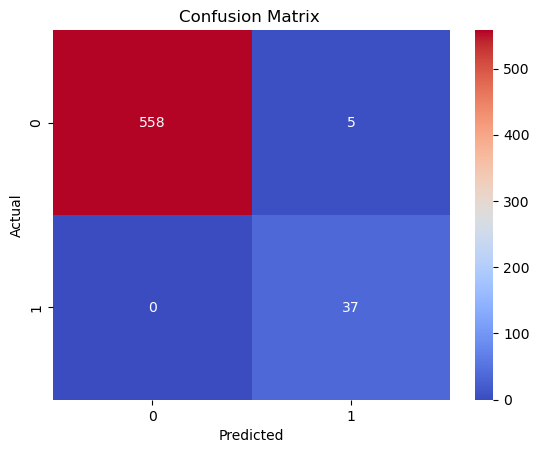

In [147]:
cm = confusion_matrix(y_pred_grid , y_test)

sns.heatmap(cm , cmap = 'coolwarm', fmt= "g" , annot = True)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix ')
plt.show()

In [148]:
X_train.columns

Index(['Age', 'MonthlyIncome', 'JobSatisfaction', 'DistanceFromHome',
       'YearsAtCompany', 'OverTime'],
      dtype='object')

In [156]:
import gradio as gr
model = best_model

In [160]:
FEATURES = [
    "Age",
    "MonthlyIncome",
    "JobSatisfaction",
    "DistanceFromHome",
    "YearsAtCompany",
    "OverTime"
]

def predict_attrition(
    Age,
    MonthlyIncome,
    JobSatisfaction,
    DistanceFromHome,
    YearsAtCompany,
    OverTime
):
    # تحويل OverTime إلى نفس الترميز المستخدم في التدريب
    overtime_value = 1 if OverTime == "Yes" else 0

    input_data = pd.DataFrame([{
        "Age": Age,
        "MonthlyIncome": MonthlyIncome,
        "JobSatisfaction": JobSatisfaction,
        "DistanceFromHome": DistanceFromHome,
        "YearsAtCompany": YearsAtCompany,
        "OverTime": overtime_value
    }], columns=FEATURES)

    # التنبؤ
    prediction = model.predict(input_data)[0]

    # عرض النتيجة
    if prediction in [1, "Yes", "Attrition"]:
        result = "Employee may leave the company"
    else:
        result = "Employee may stay at the company"

    return {
           "Prediction": {1: "Yes", 0: "No"}.get(prediction, str(prediction)),
            "Result": result
    }


demo = gr.Interface(
    fn=predict_attrition,
    inputs=[
        gr.Slider(
            minimum=18, maximum=65,
            value=30, step=1,
            label="Age"
        ),
        gr.Number(
            value=5000,
            label="Monthly Income"
        ),
        gr.Dropdown(
            choices=[1, 2, 3, 4],
            value=3,
            label="Job Satisfaction (1–4)"
        ),
        gr.Number(
            value=5,
            label="Distance From Home"
        ),
        gr.Slider(
            minimum=0, maximum=40,
            value=3, step=1,
            label="Years At Company"
        ),
        gr.Radio(
            choices=["Yes", "No"],
            value="No",
            label="OverTime"
        )
    ],
    outputs=gr.JSON(label="Prediction Result"),
    title="Employee Attrition Prediction",
    description=(
        "Enter employee information to predict "
        "whether the employee may leave the company."
    ),
    submit_btn="Predict Attrition",
    clear_btn="Clear"
)

demo.launch()


* Running on local URL:  http://127.0.0.1:7866
* To create a public link, set `share=True` in `launch()`.
